# Show mooring system and intra-array power cable layouts
Code originally built in MATALB by Synne H. Nyboe, translated to Python by help of Microsoft Copilot.

PYTHON code enabling visualization of mooring system and intra-array power cable layouts.

Requires user-input and the files in the .\resources folder.

For each plot, it is required to give suspended cable (SC) topology number, the FWT connected to the substation cable connection (SCC), and the orientation of the SCC.

System A and System B are two shared mooring systems, described in (TODO: Add ref. to article)

In [15]:
from plotSettings import(read_coordinates, read_sc_topologies, read_line_names, plot_sc_scc_layout)
import matplotlib.pyplot as plt

## User-input
System A: shared mooring system based on the CYBERLAB system, Rajasree, V.R.N., 2026. *Dynamic behaviour of floating wind farms with shared mooring in waves - Part I: Cyber-physical testing*. Ocean Engineering. https://doi.org/10.1016/j.oceaneng.2026.124176 

System B: shared mooring system based on the HoneyMooring system, Sandal, K., et. al, 2025. *Honeymooring Reference Designs for ShallowWater*. Journal of Physics: Conference Series 3131, 012026, doi:10.1088/1742-6596/3131/1/012026

The following input must be given for each plot: 
- SC : SC (suspended cable) topology numbers
- SCC_FWT : Defines which FWT the SCC (substation connection cable) is connected to
- SCC_orient: Defines the orientation of the SCC ($\theta_{SCC}$, step size $45^\circ$ between $0^\circ$ to $315^\circ$)

Overview of the number of items for System A and System B:
System | # of FWTs | # of $\theta_{SCC}$ | # of SC | # of SC topologies| # of SCC | Total # of layouts
| --- | --- | --- | --- | --- | --- | ---
A | 9 | 8 | 8-12 | 431 | 1 |  31 032
B | 6 | 8 | 5-9 | 160 | 1 | 7 680


In [16]:
system_type = "A" # System A or System B

# Define what to plot
if system_type == "A":
    SC = [242, 243, 244]                # SC topologies
    SCC_FWT = [5, 5, 2]                 # SCC FWT number
    SCC_orient = [315, 315, 315]        # SCC orientation [deg]
else: 
    SC = [32, 53, 80]                   # SC topologies
    SCC_FWT = [5, 5, 2]                 # SCC FWT number
    SCC_orient = [270, 270, 270]        # SCC orientation [deg]

## File-input
Function reads the required files to get data for the moorin system and desired power cable layouts.

- globCoord_syst_ : Global coordinates for mooring system items (FWTs, anchors and for System B also buoys)
- SC_syst: : Definition of the SC topologies
- lineNames_syst: Definition of the mooring lines

In [17]:

coord_file = f"./resources/globCoord_syst{system_type}.txt" # Global coordinates for mooring system items
sc_file = f"./resources/SC_syst{system_type}.txt"           # Definition of SC topologies
line_file = f"./resources/lineNames_syst{system_type}.txt"  # Name of all mooring lines

# Get all possible layouts from file
layouts = read_sc_topologies(sc_file)

# Get line names
line_names = read_line_names(line_file)

# Get system coordinates (initial)
plat, anch, buoy = read_coordinates(coord_file)


## Plot Mooring System and Intra-Array Power Cable layouts
Functions plotting the power cable layouts

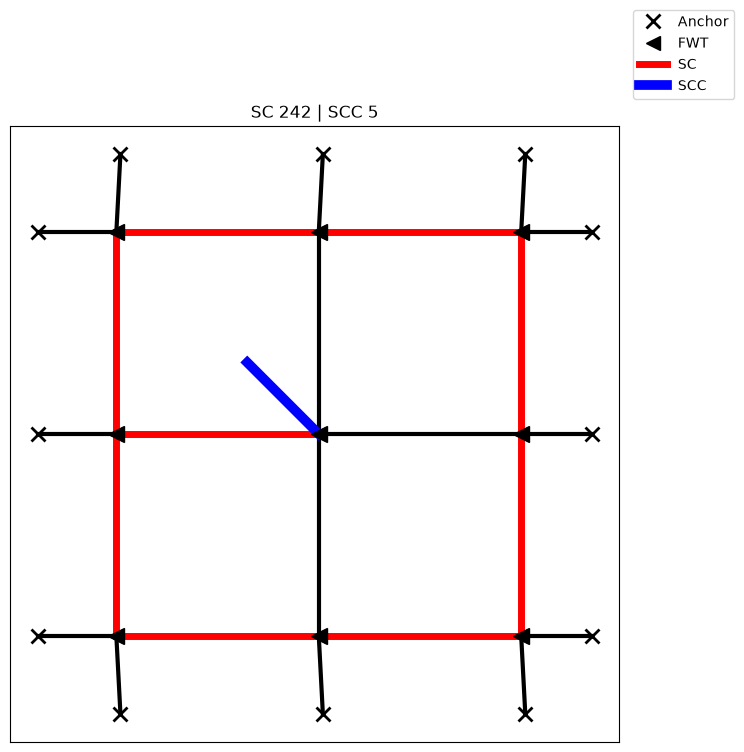

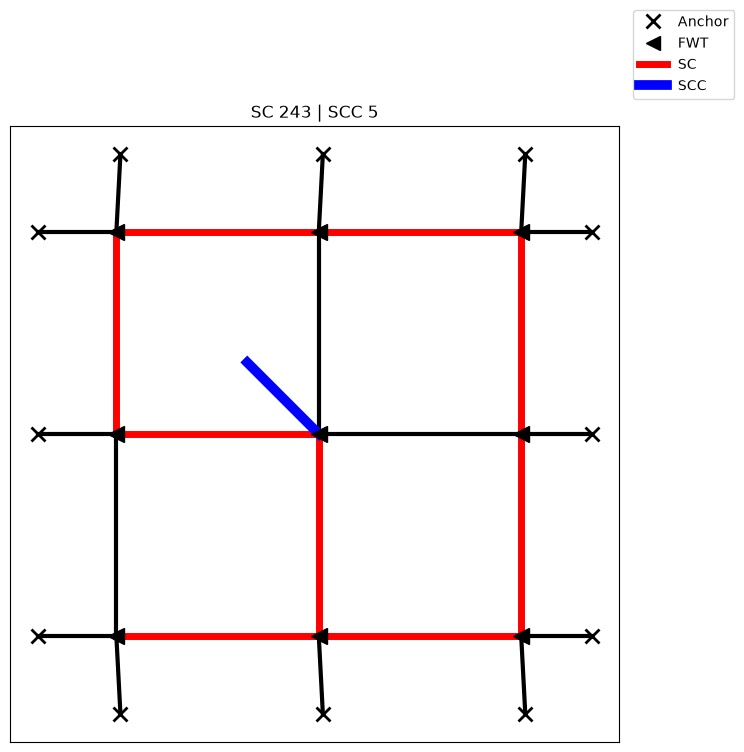

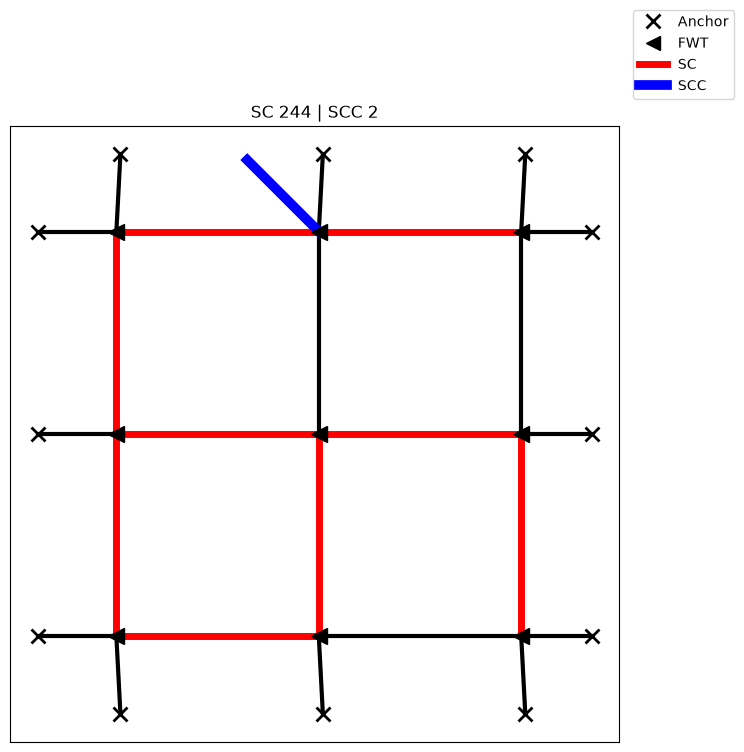

In [18]:
for sc, scc, orient in zip(SC, SCC_FWT, SCC_orient):

    layout = layouts[sc-1]

    plot_sc_scc_layout(
            plat=plat,
            anch=anch,
            buoy=buoy,
            layout=layout,
            sc_topology=sc,
            scc_FWT=scc,
            scc_or=orient,
            system_type=system_type,
            line_names=line_names,
        )
    
plt.show()